# Data Challenge 2026–2027 · EasyVista — SLA prediction in ITSM

Notebook di partenza per le due task:
1. **Classificazione**: lo SLA del ticket verrà violato?
2. **Regressione**: quanto tempo servirà per risolvere il ticket?

Struttura:
1. Caricamento e pulizia
2. Definizione dei target
3. Feature engineering (solo informazioni disponibili **all'apertura** del ticket, più uno scenario "oracle" con feature successive)
4. Split temporale train / validation / test
5. Task 1: baseline e LightGBM per la violazione dello SLA
6. Task 2: baseline e LightGBM per il tempo di risoluzione
7. Collegamento tra le due task e prossimi passi

**Requisiti:** `pandas numpy scikit-learn lightgbm matplotlib holidays`

### Setup (Colab)
Run these two cells first. The first one writes `prep.py` (shared data preparation) into the working folder, so you do not need to upload it. The second installs the missing libraries and asks you to upload `raw_EV_data_challenge.csv`.

In [ ]:
%%writefile prep.py
"""Shared data preparation for the EasyVista Data Challenge (SLA prediction).

Usage:
    from prep import load_data, CAT_CREATE, NUM_CREATE, ...
    df = load_data("raw_EV_data_challenge.csv")

Changes vs. the first version (see the work guide, section 3):
  * calendar features use Paris local time instead of UTC                     (issue 5)
  * `sla_nominal`: deadline length known at submission, replaces the
    recorded `sla_real_hours`, which looks recomputed during the ticket life (issue 1)
  * `open_recent_30d`: alternative load counter on the last 30 days only (issue 3).
    The rolling CV prefers the original cumulative counter, so it stays in NUM_CREATE
    and the 30-day version is kept in RECENT_LOAD for the ablation
  * `never_closed` flag, to report metrics with and without these tickets    (issue 4)
"""
import numpy as np
import pandas as pd
import holidays

DATE_COLS = ["SUBMIT_DATE_UT", "MAX_RESOLUTION_DATE_UT", "END_DATE_UT"]
VALID_START = pd.Timestamp("2024-01-01")
TEST_START = pd.Timestamp("2024-04-01")
REG_TEST_END = pd.Timestamp("2024-08-01")   # margin against censoring for the "plain" regression test
LOCAL_TZ = "Europe/Paris"                   # timestamps are UTC; business hours follow Paris time
LOAD_WINDOW_DAYS = 30                       # look-back window for the load feature

# Features known when the ticket is created (no leakage)
CAT_CREATE = ["SD_CATALOG_PATH_EN", "URGENCY_VALUE", "IMPACT_VALUE", "SLA_DELAY", "REQUEST_ORIGIN", "SUBMITTED_BY_ID"]
NUM_CREATE = ["sla_nominal", "hour", "dow", "month", "is_weekend", "is_holiday", "off_hours",
              "submitter_missing", "open_tickets_at_submit", "open_same_type_at_submit",
              "arrivals_24h", "arrivals_7d", "submitter_prev_tickets"]

# Kept only for ablations
LEAK_SUSPECT = ["sla_real_hours"]                                  # recorded deadline length (likely leak)
RECENT_LOAD = ["open_recent_30d", "open_recent_30d_same_type"]     # 30-day load counters (no time trend)
CUMULATIVE_LOAD = ["open_tickets_at_submit", "open_same_type_at_submit"]  # in NUM_CREATE; trends with time

# "Oracle" features, known only after the ticket is closed (upper bound, never for production)
CAT_ORACLE = ["LAST_DONE_BY_ID", "STATUS_EN"]
NUM_ORACLE = ["nb_actions"]

MIN_HOURS = 1 / 60  # 1 minute: minimum duration, avoids log(0) in survival models


def load_data(path):
    df = pd.read_csv(path, sep=";", na_values=["NULL"])
    for c in DATE_COLS:
        df[c] = pd.to_datetime(df[c]).astype("datetime64[ns]")
    df = df.sort_values("SUBMIT_DATE_UT").reset_index(drop=True)

    # Impossible closing dates (before submission, e.g. 1900-01-01) -> missing
    df.loc[df["END_DATE_UT"] < df["SUBMIT_DATE_UT"], "END_DATE_UT"] = pd.NaT
    extract = max(df["SUBMIT_DATE_UT"].max(), df["END_DATE_UT"].max())
    df.attrs["extract_date"] = extract

    # Targets, as known at the extraction date
    df["viol"] = viol_as_of(df, extract)
    df["res_hours"] = (df["END_DATE_UT"] - df["SUBMIT_DATE_UT"]).dt.total_seconds() / 3600
    df["never_closed"] = df["END_DATE_UT"].isna().astype(int)

    t = df["SUBMIT_DATE_UT"]
    df["split"] = np.where(t < VALID_START, "train", np.where(t < TEST_START, "valid", "test"))
    _add_features(df)
    return df


def viol_as_of(df, cutoff):
    """SLA-violation label as it would have been known at date `cutoff`.
    1   = deadline passed without closure (or closed after the deadline), known if deadline < cutoff
    0   = closed within the deadline, known if closure <= cutoff
    NaN = still unknown at that date (or ticket without SLA)."""
    end, dl = df["END_DATE_UT"], df["MAX_RESOLUTION_DATE_UT"]
    out = pd.Series(np.nan, index=df.index)
    ok0 = dl.notna() & end.notna() & (end <= dl) & (end <= cutoff)
    ok1 = dl.notna() & (dl < cutoff) & (end.isna() | (end > dl))
    out[ok0] = 0.0
    out[ok1] = 1.0
    return out


def duration_as_of(df, cutoff):
    """Duration in hours and event indicator as known at date `cutoff`.
    Tickets not closed by `cutoff` are right-censored at (cutoff - submission)."""
    end = df["END_DATE_UT"]
    observed = end.notna() & (end <= cutoff)
    stop = end.where(observed, cutoff)
    dur = ((stop - df["SUBMIT_DATE_UT"]).dt.total_seconds() / 3600).clip(lower=MIN_HOURS)
    return dur, observed.astype(int)


def _open_recent(sub_ns, end_ns, window_ns):
    """For each ticket: how many tickets submitted in the previous `window_ns` are still open at its submission.
    Arrays must be sorted by submission time. Uses only information available at submission."""
    first = np.searchsorted(sub_ns, sub_ns - window_ns, side="left")
    before = np.searchsorted(sub_ns, sub_ns, side="left")
    out = np.empty(len(sub_ns), dtype=np.int64)
    for i in range(len(sub_ns)):
        out[i] = np.count_nonzero(end_ns[first[i]:before[i]] >= sub_ns[i])
    return out


def _add_features(df):
    t = df["SUBMIT_DATE_UT"]

    # Recorded deadline length (suspected leakage: kept only for ablations)
    df["sla_real_hours"] = (df["MAX_RESOLUTION_DATE_UT"] - t).dt.total_seconds() / 3600

    # Calendar features in Paris local time (handles daylight saving)
    loc = t.dt.tz_localize("UTC").dt.tz_convert(LOCAL_TZ).dt.tz_localize(None)
    df["hour"] = loc.dt.hour
    df["dow"] = loc.dt.dayofweek
    df["month"] = loc.dt.month
    df["is_weekend"] = (df["dow"] >= 5).astype(int)
    fr = holidays.France(years=range(loc.dt.year.min(), loc.dt.year.max() + 1))
    df["is_holiday"] = loc.dt.date.map(lambda d: d in fr).astype(int)
    df["off_hours"] = ((df["hour"] < 8) | (df["hour"] >= 18) | (df["is_weekend"] == 1)
                       | (df["is_holiday"] == 1)).astype(int)
    df["submitter_missing"] = df["SUBMITTED_BY_ID"].isna().astype(int)

    # Nominal deadline length, known at submission: median recorded length for the same
    # SLA_DELAY and hour of the week, estimated on the training period only
    # (a missing SLA_DELAY is treated as its own group: ~130 tickets have a deadline but no SLA_DELAY).
    # The median is robust to the ~9% of deadlines that are extended later on.
    df["hour_of_week"] = df["dow"] * 24 + df["hour"]
    tr = df["split"] == "train"
    by_slot = df[tr].groupby(["SLA_DELAY", "hour_of_week"], dropna=False)["sla_real_hours"].median().rename("_slot")
    by_delay = df[tr].groupby("SLA_DELAY", dropna=False)["sla_real_hours"].median().rename("_delay")
    nom = (df[["SLA_DELAY", "hour_of_week"]]
           .merge(by_slot, left_on=["SLA_DELAY", "hour_of_week"], right_index=True, how="left")
           .merge(by_delay, left_on="SLA_DELAY", right_index=True, how="left"))
    df["sla_nominal"] = nom["_slot"].fillna(nom["_delay"]).values   # fallback: median per SLA_DELAY
    # Diagnostic only (uses the recorded deadline): deadline clearly longer than the nominal one
    df["deadline_extended"] = ((df["sla_real_hours"] > 1.5 * df["sla_nominal"])
                               & (df["sla_real_hours"] - df["sla_nominal"] > 24)).astype(int)

    # System load: only information known at submission
    sub_ns = t.values.astype("datetime64[ns]").astype("int64")
    end_ns = df["END_DATE_UT"].values.astype("datetime64[ns]").astype("int64")
    end_ns = np.where(df["END_DATE_UT"].isna(), np.iinfo("int64").max, end_ns)  # never closed = open forever
    n_before = np.searchsorted(sub_ns, sub_ns, side="left")
    day = np.int64(24 * 3600 * 10**9)

    # Cumulative counters (all tickets ever opened and still open). They grow with time because
    # never-closed tickets pile up and the data starts at zero in Sep 2022, but the rolling CV
    # still prefers them to the 30-day version: keep them, and do not read their SHAP plot as a pure load effect
    df["open_tickets_at_submit"] = n_before - np.searchsorted(np.sort(end_ns), sub_ns, side="left")
    df["open_same_type_at_submit"] = 0
    # 30-day counters: only tickets submitted in the last LOAD_WINDOW_DAYS (the first month of data is a warm-up)
    win = LOAD_WINDOW_DAYS * day
    df["open_recent_30d"] = _open_recent(sub_ns, end_ns, win)
    df["open_recent_30d_same_type"] = 0
    for _, idx in df.groupby("SD_CATALOG_PATH_EN").groups.items():
        s, e = sub_ns[idx], end_ns[idx]
        df.loc[idx, "open_same_type_at_submit"] = np.searchsorted(s, s, side="left") - np.searchsorted(np.sort(e), s, side="left")
        df.loc[idx, "open_recent_30d_same_type"] = _open_recent(s, e, win)

    df["arrivals_24h"] = n_before - np.searchsorted(sub_ns, sub_ns - day, side="left")
    df["arrivals_7d"] = n_before - np.searchsorted(sub_ns, sub_ns - 7 * day, side="left")

    # Submitter history: number of tickets opened before this one (-1 = unknown submitter)
    df["submitter_prev_tickets"] = df.groupby("SUBMITTED_BY_ID").cumcount()
    df.loc[df["SUBMITTED_BY_ID"].isna(), "submitter_prev_tickets"] = -1


def prepare_cats(frame, cats, train_mask, min_count=20):
    """Categoricals as 'category' dtype (LightGBM/XGBoost); rare or unseen levels in train -> '__other__'."""
    X = frame.copy()
    for c in cats:
        s = X[c].astype("string").fillna("__missing__")
        vc = s[train_mask].value_counts()
        keep = set(vc[vc >= min_count].index)
        X[c] = pd.Categorical(s.where(s.isin(keep), "__other__"))
    return X


In [ ]:
# Colab setup: install the libraries that Colab does not preinstall,
# then upload the CSV if it is not in the working folder yet (prep.py is written by the cell above).
!pip install -q catboost lifelines holidays
import os
if not os.path.exists("raw_EV_data_challenge.csv"):
    try:
        from google.colab import files
        print("Please upload raw_EV_data_challenge.csv")
        files.upload()
    except ImportError:
        print("Put raw_EV_data_challenge.csv next to the notebook.")
else:
    print("CSV found.")

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import holidays
import lightgbm as lgb
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score,
                             precision_score, recall_score, mean_absolute_error,
                             median_absolute_error, precision_recall_curve)

SEED = 42
DATA_PATH = "raw_EV_data_challenge.csv"

# palette (colorblind-safe, ordine fisso)
BLUE, ORANGE, AQUA, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#e1e0d9"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
                     "axes.axisbelow": True, "figure.dpi": 110})
pd.set_option("display.width", 140)

## 1. Caricamento e pulizia

In [2]:
# All data preparation now lives in prep.py, so both notebooks use exactly the same
# targets and features. Keep the plotting cell of section 2 as it is.
from prep import (load_data, prepare_cats, CAT_CREATE, NUM_CREATE, CAT_ORACLE, NUM_ORACLE,
                  LEAK_SUSPECT, VALID_START, TEST_START, REG_TEST_END)

df = load_data(DATA_PATH)
EXTRACT_DATE = df.attrs["extract_date"]
t = df["SUBMIT_DATE_UT"]
print(df.shape, "| period:", t.min(), "->", t.max(), "| extraction date:", EXTRACT_DATE)
print("tickets with a violation label:", df.viol.notna().sum(),
      "| of which never closed and overdue:", (df.viol.notna() & (df.never_closed == 1)).sum())
print("violation rate:", round(df.viol.mean(), 3), "| closed tickets (regression):", df.res_hours.notna().sum())
print(df.groupby("split").agg(n=("REQUEST_ID", "size"), viol_rate=("viol", "mean"),
                              res_median_h=("res_hours", "median")).round(3).loc[["train", "valid", "test"]])


(64175, 35) | period: 2022-09-16 06:04:44 -> 2024-09-16 18:25:36.993000 | extraction date: 2024-09-16 18:31:03.483000
tickets with a violation label: 59925 | of which never closed and overdue: 924
violation rate: 0.259 | closed tickets (regression): 60911
           n  viol_rate  res_median_h
split                                
train  38402      0.260        17.194
valid   9312      0.242         8.118
test   16461      0.265         7.213


## 2. Target

**Violazione SLA** (`viol`), definita solo per ticket con SLA (`MAX_RESOLUTION_DATE_UT` presente):
- ticket chiuso → `viol = END_DATE > MAX_RESOLUTION_DATE`
- ticket **non chiuso** ma con scadenza già passata alla data di estrazione → `viol = 1` (lo SLA è sicuramente violato)
- ticket non chiuso con scadenza futura → etichetta ignota, escluso

**Tempo di risoluzione** (`res_hours`): ore di calendario tra apertura e chiusura; per la regressione usiamo `log1p(res_hours)` per via della coda lunga. I ticket non chiusi sono **censurati a destra** (vedi prossimi passi: analisi di sopravvivenza).

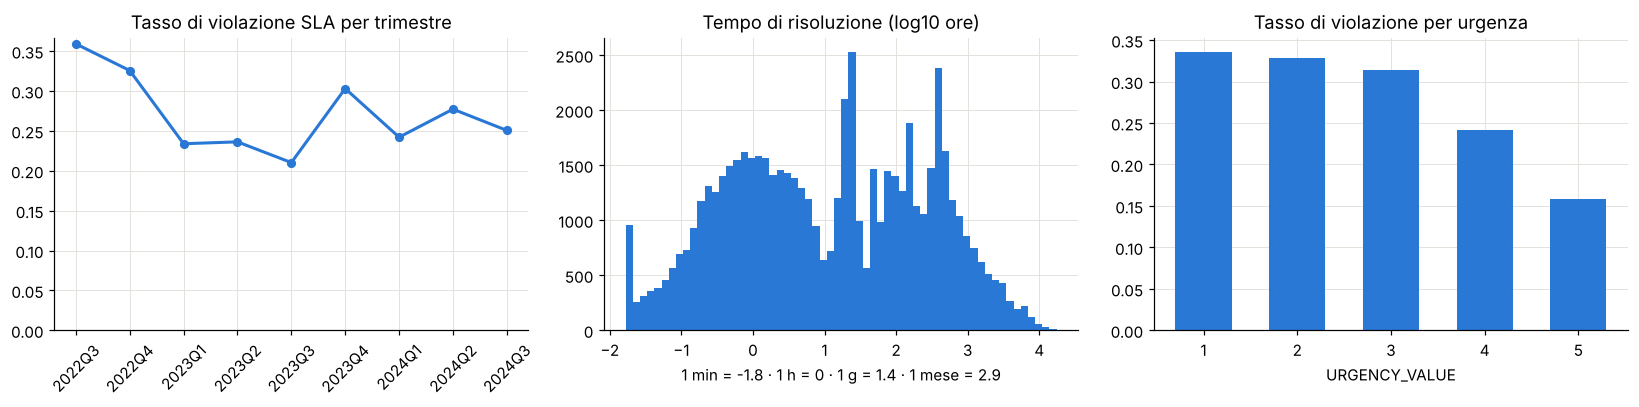

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))

q = df.dropna(subset=["viol"]).groupby(df.SUBMIT_DATE_UT.dt.to_period("Q"))["viol"].mean()
axes[0].plot(q.index.astype(str), q.values, color=BLUE, lw=2, marker="o", ms=5)
axes[0].set_title("Tasso di violazione SLA per trimestre")
axes[0].set_ylim(0, None); axes[0].tick_params(axis="x", rotation=45)

axes[1].hist(np.log10(df.res_hours.dropna().clip(lower=1/60)), bins=60, color=BLUE)
axes[1].set_title("Tempo di risoluzione (log10 ore)")
axes[1].set_xlabel("1 min = -1.8 · 1 h = 0 · 1 g = 1.4 · 1 mese = 2.9")

u = df.dropna(subset=["viol"]).groupby("URGENCY_VALUE")["viol"].mean()
axes[2].bar(u.index.astype(str), u.values, color=BLUE, width=0.6)
axes[2].set_title("Tasso di violazione per urgenza"); axes[2].set_xlabel("URGENCY_VALUE")
plt.tight_layout(); plt.show()

## 3. Feature engineering

**Feature "all'apertura"** (nessun leakage):
- categoriche: tipo di ticket, urgenza, impatto, `SLA_DELAY`, canale d'origine, richiedente
- **durata SLA reale** = `MAX_RESOLUTION − SUBMIT` in ore: `SLA_DELAY` è in ore *lavorative* secondo calendari diversi, quindi la durata reale concessa è più informativa
- calendario: ora, giorno della settimana, mese, weekend, fuori orario, festivo in Francia
- **carico del sistema**: ticket aperti al momento dell'apertura, arrivi nelle 24 h / 7 giorni precedenti
- storico del richiedente: quanti ticket ha già aperto

**Feature "oracle"** (note solo a posteriori): `nb_actions`, `LAST_DONE_BY_ID`, `STATUS_EN`. Le usiamo solo per misurare il gap rispetto allo scenario realistico.

> **v2:** features are now built in `prep.py`. The deadline length is the *nominal* one (`sla_nominal`, median for the same `SLA_DELAY` and hour of week, estimated on train), because the recorded deadline seems to be moved during the ticket's life. Calendar features use Paris local time.

## 4. Split temporale

Il tasso di violazione cambia nel tempo, quindi uno split casuale sarebbe troppo ottimistico. Usiamo:
- **train**: set 2022 → dic 2023
- **validation**: gen → mar 2024 (early stopping, scelta della soglia)
- **test**: apr → set 2024

Nota: per la regressione i ticket aperti a fine periodo e ancora non chiusi mancano, quindi il test sottostima i ticket lunghi (censura). Per questo valutiamo la regressione solo su ticket aperti entro il **31 luglio 2024** (≈ 7 settimane di margine).

## 5. Task 1: violazione dello SLA (classificazione)

In [10]:
cls = df[df["viol"].notna()].copy()
cls["viol"] = cls["viol"].astype(int)
tr, va, te = (cls["split"] == s for s in ["train", "valid", "test"])
print("train/valid/test:", tr.sum(), va.sum(), te.sum())

results_cls = []

def eval_cls(name, p_valid, p_test, y_valid, y_test):
    # soglia scelta sulla validation (max F1), poi applicata al test
    prec, rec, thr = precision_recall_curve(y_valid, p_valid)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-9, None)
    th = thr[np.nanargmax(f1[:-1])]
    yhat = (p_test >= th).astype(int)
    r = dict(model=name, ROC_AUC=roc_auc_score(y_test, p_test), PR_AUC=average_precision_score(y_test, p_test),
             threshold=th, F1=f1_score(y_test, yhat), precision=precision_score(y_test, yhat),
             recall=recall_score(y_test, yhat))
    results_cls.append(r)
    return r

y_va, y_te = cls.loc[va, "viol"].values, cls.loc[te, "viol"].values

train/valid/test: 35803 8792 15330


**Baseline 0**: tasso di violazione storico per gruppo (tipo × urgenza × SLA_DELAY), stimato sul train.

In [11]:
grp = ["SD_CATALOG_PATH_EN", "URGENCY_VALUE", "SLA_DELAY"]
rates = cls[tr].groupby(grp, dropna=False)["viol"].mean().rename("p_grp")
prior = cls.loc[tr, "viol"].mean()
p_grp = cls[grp].merge(rates, left_on=grp, right_index=True, how="left")["p_grp"].fillna(prior).values
eval_cls("Baseline: tasso per gruppo", p_grp[va.values], p_grp[te.values], y_va, y_te)

{'model': 'Baseline: tasso per gruppo',
 'ROC_AUC': 0.5918284764904786,
 'PR_AUC': 0.3149362526945324,
 'threshold': np.float64(0.0),
 'F1': 0.41909869031659275,
 'precision': 0.2651011089367254,
 'recall': 1.0}

**Baseline 1**: regressione logistica (one-hot + feature numeriche standardizzate), solo feature all'apertura.

In [12]:
lr_cats = [c for c in CAT_CREATE if c != "SUBMITTED_BY_ID"]
Xl = cls[lr_cats + NUM_CREATE].copy()
for c in lr_cats:
    Xl[c] = Xl[c].astype("string").fillna("NA")
Xl["log_sla_real"] = np.log1p(Xl["sla_nominal"].clip(lower=0))
num_l = NUM_CREATE + ["log_sla_real"]
pre = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), lr_cats),
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), num_l)])
logreg = make_pipeline(pre, LogisticRegression(max_iter=2000, C=1.0))
logreg.fit(Xl[tr], cls.loc[tr, "viol"])
eval_cls("Logistic regression (apertura)", logreg.predict_proba(Xl[va])[:, 1],
         logreg.predict_proba(Xl[te])[:, 1], y_va, y_te)

{'model': 'Logistic regression (apertura)',
 'ROC_AUC': 0.6093970159325459,
 'PR_AUC': 0.33806745050011233,
 'threshold': np.float64(0.16660359612592665),
 'F1': 0.43141852286049237,
 'precision': 0.3404982206405694,
 'recall': 0.5885826771653543}

**Modello principale**: LightGBM con feature all'apertura, poi lo stesso con le feature "oracle".

In [13]:
LGB_CLS = dict(objective="binary", learning_rate=0.03, num_leaves=63, min_child_samples=40,
               feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0,
               verbose=-1, seed=SEED)

def fit_lgb_cls(cats, nums, name):
    X = prepare_cats(cls[cats + nums], cats, tr)
    dtr = lgb.Dataset(X[tr], cls.loc[tr, "viol"], categorical_feature=cats)
    dva = lgb.Dataset(X[va], cls.loc[va, "viol"], categorical_feature=cats, reference=dtr)
    m = lgb.train(LGB_CLS, dtr, 3000, valid_sets=[dva],
                  callbacks=[lgb.early_stopping(150, verbose=False)])
    pv, pt = m.predict(X[va], num_iteration=m.best_iteration), m.predict(X[te], num_iteration=m.best_iteration)
    eval_cls(name, pv, pt, y_va, y_te)
    return m, X, pt

m_cls, X_cls, p_te_cls = fit_lgb_cls(CAT_CREATE, NUM_CREATE, "LightGBM (apertura)")
m_cls_or, _, _ = fit_lgb_cls(CAT_CREATE + CAT_ORACLE, NUM_CREATE + NUM_ORACLE, "LightGBM + oracle (a posteriori)")

res_cls = pd.DataFrame(results_cls).set_index("model").round(3)
print(f"Tasso di violazione nel test: {y_te.mean():.3f}  (= PR-AUC di un classificatore casuale)")
res_cls

Tasso di violazione nel test: 0.265  (= PR-AUC di un classificatore casuale)


,ROC_AUC,PR_AUC,threshold,F1,precision,recall
model,,,,,,
Baseline: tasso per gruppo,0.592,0.315,0.000,0.419,0.265,1.000
Logistic regression (apertura),0.609,0.338,0.167,0.431,0.340,0.589
LightGBM (apertura),0.697,0.450,0.234,0.497,0.372,0.749
LightGBM + oracle (a posteriori),0.820,0.640,0.225,0.577,0.444,0.823


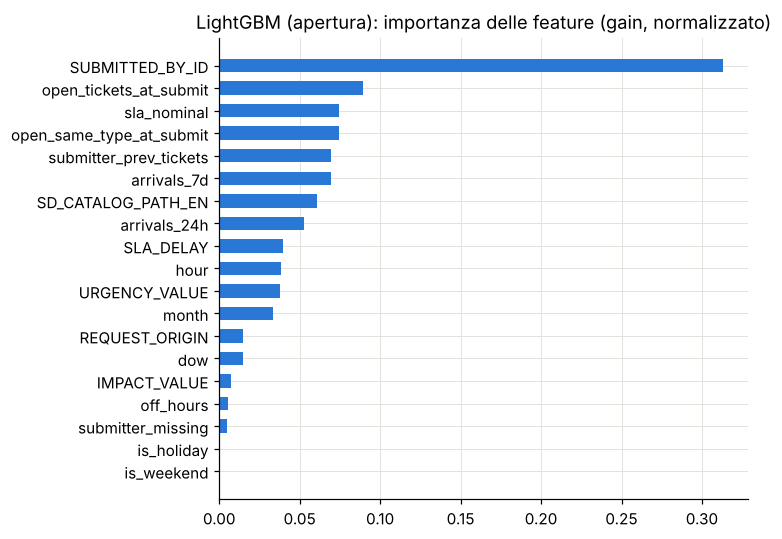

In [14]:
imp = pd.Series(m_cls.feature_importance("gain"), index=m_cls.feature_name()).sort_values()
imp = imp / imp.sum()
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(imp.index, imp.values, color=BLUE, height=0.6)
ax.set_title("LightGBM (apertura): importanza delle feature (gain, normalizzato)")
plt.tight_layout(); plt.show()

In [15]:
# Performance per tipo di ticket sul test
te_df = cls[te].assign(p=p_te_cls)
te_df.groupby("SD_CATALOG_PATH_EN").apply(
    lambda g: pd.Series({"n": len(g), "viol_rate": g.viol.mean(),
                         "ROC_AUC": roc_auc_score(g.viol, g.p) if g.viol.nunique() > 1 else np.nan,
                         "PR_AUC": average_precision_score(g.viol, g.p) if g.viol.nunique() > 1 else np.nan})
).round(3)

,n,viol_rate,ROC_AUC,PR_AUC
SD_CATALOG_PATH_EN,,,,
Change,1.0,0.000,NaN,NaN
Incidents,9073.0,0.332,0.635,0.467
Service Request,6255.0,0.168,0.703,0.362


## 6. Task 2: tempo di risoluzione (regressione)

Target: `log1p(res_hours)`. Usiamo tutti i ticket chiusi, compresi Change e Problem. Metriche:
- **MAE (ore)**: errore medio in ore, molto influenzato dalla coda lunga
- **MedAE (ore)**: errore mediano in ore
- **MAE log**: errore medio sulla scala logaritmica, cioè un errore *relativo*. MAE log = 1 vuol dire che in media si sbaglia di un fattore e ≈ 2.7.

In [16]:
reg = df[df["res_hours"].notna()].copy()
reg = reg[~((reg["split"] == "test") & (reg["SUBMIT_DATE_UT"] >= REG_TEST_END))]
reg["y"] = np.log1p(reg["res_hours"])
rtr, rva, rte = (reg["split"] == s for s in ["train", "valid", "test"])
print("train/valid/test:", rtr.sum(), rva.sum(), rte.sum())

results_reg = []
def eval_reg(name, pred_log, mask):
    y, yh = reg.loc[mask, "y"].values, pred_log
    h, hh = np.expm1(y), np.expm1(yh)
    results_reg.append(dict(model=name, MAE_hours=mean_absolute_error(h, hh),
                            MedAE_hours=median_absolute_error(h, hh), MAE_log=mean_absolute_error(y, yh)))

# Baseline 0: mediana globale; Baseline 1: mediana per gruppo (tipo × urgenza × SLA_DELAY)
eval_reg("Baseline: mediana globale", np.full(rte.sum(), reg.loc[rtr, "y"].median()), rte)
med = reg[rtr].groupby(grp, dropna=False)["y"].median().rename("m")
pg = reg[grp].merge(med, left_on=grp, right_index=True, how="left")["m"].fillna(reg.loc[rtr, "y"].median()).values
eval_reg("Baseline: mediana per gruppo", pg[rte.values], rte)

train/valid/test: 36772 8960 11872


In [17]:
LGB_REG = dict(objective="regression_l1", learning_rate=0.03, num_leaves=63, min_child_samples=40,
               feature_fraction=0.8, bagging_fraction=0.8, bagging_freq=1, lambda_l2=1.0,
               verbose=-1, seed=SEED)

def fit_lgb_reg(cats, nums, name):
    X = prepare_cats(reg[cats + nums], cats, rtr)
    dtr = lgb.Dataset(X[rtr], reg.loc[rtr, "y"], categorical_feature=cats)
    dva = lgb.Dataset(X[rva], reg.loc[rva, "y"], categorical_feature=cats, reference=dtr)
    m = lgb.train(LGB_REG, dtr, 3000, valid_sets=[dva], callbacks=[lgb.early_stopping(150, verbose=False)])
    pt = m.predict(X[rte], num_iteration=m.best_iteration)
    eval_reg(name, pt, rte)
    return m, pt

m_reg, pred_te_reg = fit_lgb_reg(CAT_CREATE, NUM_CREATE, "LightGBM L1 (apertura)")
m_reg_or, _ = fit_lgb_reg(CAT_CREATE + CAT_ORACLE, NUM_CREATE + NUM_ORACLE, "LightGBM L1 + oracle (a posteriori)")

res_reg = pd.DataFrame(results_reg).set_index("model").round(2)
res_reg

,MAE_hours,MedAE_hours,MAE_log
model,,,
Baseline: mediana globale,135.46,16.94,2.01
Baseline: mediana per gruppo,183.10,41.56,1.81
LightGBM L1 (apertura),132.99,21.01,1.61
LightGBM L1 + oracle (a posteriori),116.12,13.38,1.18


### Regression benchmark
Several methods on the same temporal split (Ridge, HistGradientBoosting, CatBoost, LightGBM), plus an ablation with the recorded deadline length to show the size of the leak.

In [18]:
# Benchmark of several regression methods on the same split (brief: "compare several
# methods"). Target = log1p(hours); every model is trained on the train period,
# tuned/early-stopped on validation where possible, evaluated on the test period.
from sklearn.linear_model import Ridge
from sklearn.ensemble import HistGradientBoostingRegressor
from catboost import CatBoostRegressor

reg_cats = [c for c in CAT_CREATE if c != "SUBMITTED_BY_ID"]   # high-cardinality ID only for tree models
X_reg = reg[reg_cats + NUM_CREATE].copy()
for c in reg_cats:
    X_reg[c] = X_reg[c].astype("string").fillna("NA")
pre_reg = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=20), reg_cats),
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), NUM_CREATE)])

# 1) Ridge regression on log1p(hours): linear reference model
ridge = make_pipeline(pre_reg, Ridge(alpha=1.0)).fit(X_reg[rtr], reg.loc[rtr, "y"])
eval_reg("Ridge (log1p)", ridge.predict(X_reg[rte]), rte)

# 2) Histogram gradient boosting with absolute-error loss (scikit-learn).
#    It accepts at most 255 levels per categorical, so the submitter ID is left out here too.
X_hgb = prepare_cats(reg[reg_cats + NUM_CREATE], reg_cats, rtr)
hgb = HistGradientBoostingRegressor(loss="absolute_error", learning_rate=0.05, max_iter=2000,
                                    categorical_features="from_dtype", early_stopping=True,
                                    validation_fraction=0.15, n_iter_no_change=50, random_state=SEED)
hgb.fit(X_hgb[rtr | rva], reg.loc[rtr | rva, "y"])   # uses its own internal validation split
eval_reg("HistGradientBoosting L1", hgb.predict(X_hgb[rte]), rte)

# 3) CatBoost with MAE loss and native categorical handling (submitter ID included)
X_cb = prepare_cats(reg[CAT_CREATE + NUM_CREATE], CAT_CREATE, rtr)
for c in CAT_CREATE:
    X_cb[c] = X_cb[c].astype(str)
cb = CatBoostRegressor(loss_function="MAE", iterations=3000, learning_rate=0.06, depth=6,
                       od_type="Iter", od_wait=150, random_seed=SEED, verbose=0)
cb.fit(X_cb[rtr], reg.loc[rtr, "y"], cat_features=CAT_CREATE,
       eval_set=(X_cb[rva], reg.loc[rva, "y"]), use_best_model=True)
eval_reg("CatBoost MAE", cb.predict(X_cb[rte]), rte)

# 4) Ablation: LightGBM with the recorded deadline length, to show the size of the leak (issue 1)
fit_lgb_reg(CAT_CREATE, NUM_CREATE + LEAK_SUSPECT, "LightGBM L1 + recorded deadline (leak, do not use)")

res_reg = pd.DataFrame(results_reg).set_index("model").round(2)
res_reg.sort_values("MAE_log")


,MAE_hours,MedAE_hours,MAE_log
model,,,
LightGBM L1 + oracle (a posteriori),116.12,13.38,1.18
"LightGBM L1 + recorded deadline (leak, do not use)",108.47,13.20,1.34
HistGradientBoosting L1,131.25,17.09,1.58
CatBoost MAE,133.27,21.01,1.60
LightGBM L1 (apertura),132.99,21.01,1.61
Ridge (log1p),133.59,21.64,1.77
Baseline: mediana per gruppo,183.10,41.56,1.81
Baseline: mediana globale,135.46,16.94,2.01


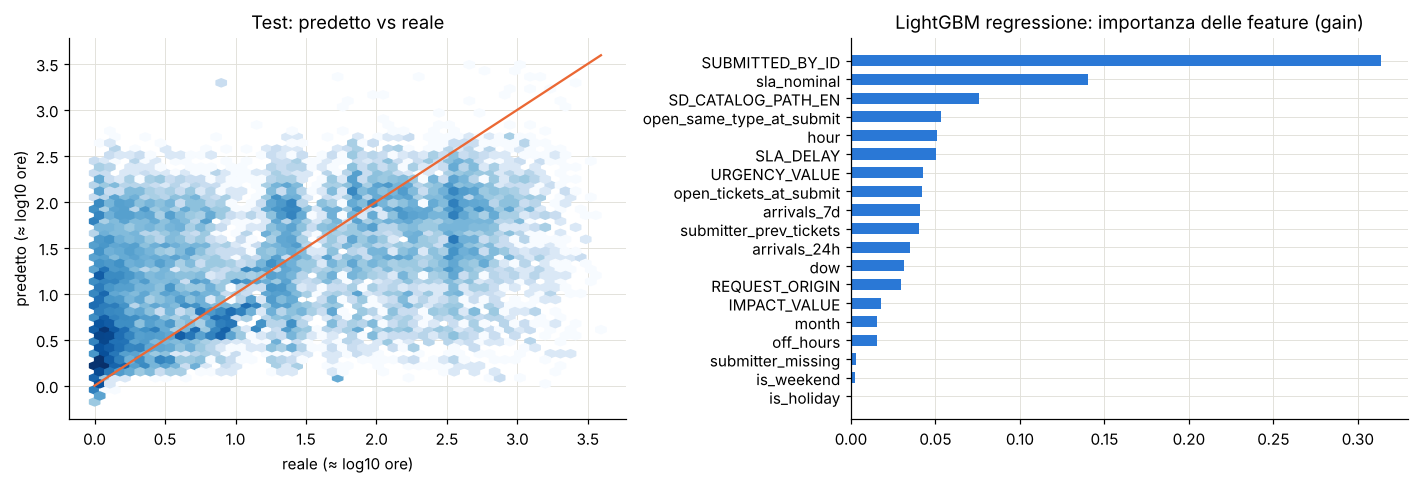

In [19]:
yt = reg.loc[rte, "y"].values
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hexbin(yt / np.log(10), pred_te_reg / np.log(10), gridsize=50, cmap="Blues", mincnt=1, bins="log")
lim = [0, max(yt.max(), pred_te_reg.max()) / np.log(10)]
axes[0].plot(lim, lim, color=ORANGE, lw=1.5)
axes[0].set_xlabel("reale (≈ log10 ore)"); axes[0].set_ylabel("predetto (≈ log10 ore)")
axes[0].set_title("Test: predetto vs reale")

imp_r = pd.Series(m_reg.feature_importance("gain"), index=m_reg.feature_name()).sort_values()
imp_r = imp_r / imp_r.sum()
axes[1].barh(imp_r.index, imp_r.values, color=BLUE, height=0.6)
axes[1].set_title("LightGBM regressione: importanza delle feature (gain)")
plt.tight_layout(); plt.show()

## 7. Collegamento tra le due task

Il tempo di risoluzione previsto, confrontato con la durata SLA concessa, dà già uno *score* di violazione: `score = log1p(pred_ore) − log1p(sla_real_hours)`. Lo confrontiamo con il classificatore diretto sui ticket chiusi con SLA del test.

In [20]:
mask = rte & reg["sla_nominal"].notna() & reg["viol"].notna()
sub = reg[mask]
X_all = prepare_cats(reg[CAT_CREATE + NUM_CREATE], CAT_CREATE, rtr)
score = m_reg.predict(X_all[mask], num_iteration=m_reg.best_iteration) - np.log1p(sub["sla_nominal"].clip(lower=0))
p_direct = pd.Series(p_te_cls, index=cls[te].index).reindex(sub.index)
ok = p_direct.notna()
print(f"ticket confrontati: {ok.sum()}")
print(f"ROC-AUC  indiretto (regressione vs scadenza): {roc_auc_score(sub.viol[ok], score[ok]):.3f}")
print(f"ROC-AUC  diretto (classificatore):             {roc_auc_score(sub.viol[ok], p_direct[ok]):.3f}")

ticket confrontati: 11527
ROC-AUC  indiretto (regressione vs scadenza): 0.681
ROC-AUC  diretto (classificatore):             0.718


## Prossimi passi

1. **Analisi di sopravvivenza** per il tempo di risoluzione: usare anche i ticket non chiusi come censurati (Cox, Random Survival Forest, XGBoost/LightGBM con loss AFT).
2. **Regressione quantile** (LightGBM `objective="quantile"`) per dare intervalli invece di un valore puntuale.
3. **Tuning** con validazione temporale a finestre scorrevoli (es. `TimeSeriesSplit` o rolling origin), poi confronto con CatBoost e XGBoost.
4. **Calibrazione** delle probabilità (isotonic/Platt) e scelta della soglia in base a un costo asimmetrico (violazione non prevista vs falso allarme).
5. **Interpretabilità**: valori SHAP, analisi degli errori per tipo di ticket, canale, urgenza.
6. **Scenario "in corso d'opera"**: predire a T+1h / T+24h dall'apertura, usando solo le azioni avvenute fino a quel momento (servirebbero i log delle azioni, da chiedere a EasyVista).
7. Chiarire con EasyVista: il calendario lavorativo dietro `SLA_DELAY`, il significato di `STATUS_EN` e dei ticket mai chiusi, e se i ticket aperti e scaduti vanno davvero contati come violati.